# 学习目标

- 解释时间复杂度为什么关注输入规模增大时的变化趋势
- 使用大O记号描述常见算法的时间复杂度
- 根据循环、嵌套结构和规模缩减分析 Python 程序
- 比较算法并选择更合适的方案

## 1. 从查找问题开始

在一组无序数据中查找目标值。最坏情况下，程序必须检查列表中的每一个元素。

In [1]:
#| echo: true
def contains(values, target):
    for value in values:
        if value == target:
            return True
    return False

values = [3, 8, 2, 5]
print(contains(values, 2))

True


**观察最坏情况：按空格键逐步显示**

::: {.incremental}
- `len(values) = 4`：最多比较 **4 次**
- `len(values) = 16`：最多比较 **16 次**
:::



## 2. 什么是时间复杂度

时间复杂度描述算法的基本操作执行次数如何随输入规模 $n$ 增长。

$$
T(n)=\text{算法基本操作的执行次数}
$$

它不等于某台电脑上的实际运行秒数。时间复杂度关注输入足够大时，工作量增长得有多快。

## 3. 基本操作的执行次数

基本操作是算法中反复执行、能够代表主要工作量的一步。下面把 `total += value` 作为基本操作并进行计数。

In [2]:
#| echo: true
def count_additions(n):
    count = 0
    total = 0
    for value in range(n):
        total += value      # 基本操作
        count += 1
    return count

for n in (3, 5, 10):
    print(f"n={n:>2}, 基本操作执行次数={count_additions(n)}")

n= 3, 基本操作执行次数=3
n= 5, 基本操作执行次数=5
n=10, 基本操作执行次数=10


列表包含 $n$ 个元素，基本操作执行 $n$ 次，因此：

$$
T(n)=n=O(n)
$$


## 5. 大 O 记号与化简

若存在常数 $c$ 和 $n_0$，当 $n\ge n_0$ 时满足：

$$
0\le T(n)\le c\,f(n)
$$

则记作 $T(n)=O(f(n))$。

常用化简规则：

- 忽略常数因子，例如 $3n=O(n)$
- 忽略低阶项，例如 $n^2+20n+1=O(n^2)$
- 连续代码块的复杂度相加，最后保留增长最快的一项

## 6. 常见增长率

| 时间复杂度 | 名称 | 典型例子 |
|---|---|---|
| $O(1)$ | 常数时间 | 按下标访问列表元素 |
| $O(\log n)$ | 对数时间 | 二分查找 |
| $O(n)$ | 线性时间 | 遍历列表 |
| $O(n\log n)$ | 线性对数时间 | 高效排序 |
| $O(n^2)$ | 平方时间 | 简单的双重比较 |
| $O(2^n)$ | 指数时间 | 枚举所有子集 |



##
修改下面代码中的 `max_n`，重新运行即可比较不同输入规模下的增长率。

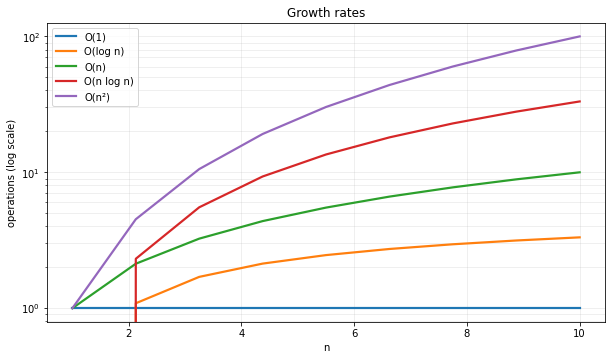

In [3]:
#| echo: true
import numpy as np
import matplotlib.pyplot as plt

max_n = 10  # 修改这里，例如 10、100、1000、10000
n = np.linspace(1, max_n, max_n-1)

# 直接按照数学表达式计算每条曲线
y_1 = np.ones_like(n)
y_log_n = np.log2(n)
y_n = n
y_n_log_n = n * np.log2(n)
y_n2 = n ** 2

plt.figure(figsize=(10, 5.5))
plt.plot(n, y_1, linewidth=2.2, label="O(1)")
plt.plot(n, y_log_n, linewidth=2.2, label="O(log n)")
plt.plot(n, y_n, linewidth=2.2, label="O(n)")
plt.plot(n, y_n_log_n, linewidth=2.2, label="O(n log n)")
plt.plot(n, y_n2, linewidth=2.2, label="O(n²)")

plt.yscale("log")
plt.xlabel("n")
plt.ylabel("operations (log scale)")
plt.title("Growth rates")
plt.grid(True, which="both", alpha=0.25)
plt.legend()
plt.show()


## 7. 单层循环：$O(n)$

In [4]:
#| echo: true
def sum_values(values):
    total = 0
    for value in values:
        total += value
    return total

print(sum_values([1, 2, 3, 4, 5]))

15


循环执行 $n$ 次，每次只做常数工作，因此：

$$
T(n)=an+b=O(n)
$$

## 8. 矩阵加法中的嵌套循环：$O(n^2)$

In [5]:
#| echo: true
def add_square_matrices(A, B):
    n = len(A)
    result = [[0] * n for _ in range(n)]

    for i in range(n):          # 遍历 n 行
        for j in range(n):      # 每行遍历 n 列
            result[i][j] = A[i][j] + B[i][j]

    return result

A = [[1, 2, 3],
     [4, 5, 6],
     [7, 8, 9]]
B = [[10, 20, 30],
     [40, 50, 60],
     [70, 80, 90]]

for row in add_square_matrices(A, B):
    print(row)


[11, 22, 33]
[44, 55, 66]
[77, 88, 99]


## 
两个矩阵都是 $n\times n$ 方阵：

- 外层循环遍历 $n$ 行
- 内层循环遍历每行的 $n$ 个位置
- 每个位置执行一次加法

基本操作的总次数为：

$$
n\times n=n^2
$$

因此矩阵加法的时间复杂度为：

$$
T(n)=O(n^2)
$$

## 9. 连续代码块：相加后取最大项

In [6]:
#| echo: true
def sequential_blocks(n):
    first_count = 0
    second_count = 0

    for _ in range(n):          # O(n)
        first_count += 1

    for _ in range(n):          # O(n^2)
        for _ in range(n):
            second_count += 1

    return first_count, second_count

print(sequential_blocks(5))

(5, 25)


$$
T(n)=O(n)+O(n^2)=O(n^2)
$$

## 10. 对半缩小：$O(\log n)$

In [7]:
#| echo: true
def binary_search(values, target):
    left, right = 0, len(values) - 1
    comparisons = 0
    while left <= right:
        comparisons += 1
        middle = (left + right) // 2
        if values[middle] == target:
            return middle, comparisons
        if values[middle] < target:
            left = middle + 1
        else:
            right = middle - 1
    return -1, comparisons

values = list(range(1, 1025))
print(binary_search(values, 1000))

(999, 7)


## 10. 对半缩小：$O(\log n)$
每次比较后，搜索范围缩小为原来的一半：

$$
\frac{n}{2^k}=1 \quad\Rightarrow\quad k=\log_2 n
$$

二分查找要求输入序列已经排序。如果数据无序且只查询一次，线性查找通常更合适。

## 11. 最好、最坏与平均情况

以线性查找为例：

| 情况 | 目标位置 | 时间复杂度 |
|---|---|---|
| 最好情况 | 第一个元素 | $O(1)$ |
| 最坏情况 | 最后一个元素或不存在 | $O(n)$ |
| 平均情况 | 中间附近 | $O(n)$ |

讨论大 O 时通常关注最坏情况，因为它给出性能上界。

## 12. 递归示例

In [3]:
#| echo: true
def factorial(n):
    if n <= 1:
        return 1
    return n * factorial(n - 1)

print(factorial(5))

120


<p>
  <a href="https://pythontutor.com/visualize.html#code=def%20factorial%28n%29%3A%0A%20%20%20%20if%20n%20%3C%3D%201%3A%0A%20%20%20%20%20%20%20%20return%201%0A%20%20%20%20return%20n%20%2A%20factorial%28n%20-%201%29%0A%0Aprint%28factorial%285%29%29&mode=display&py=311&cumulative=false&curInstr=0" target="_blank" rel="noopener noreferrer"
     style="display:inline-block;padding:0.45em 0.8em;border:1px solid #1769aa;border-radius:6px;color:#1769aa;text-decoration:none;font-weight:600;">
    ▶ 在 Python Tutor 中逐步观察递归调用栈
  </a>
</p>

点击后使用 <strong>Forward</strong> 逐步执行，重点观察每次调用产生的新栈帧，以及返回值如何逐层传回。

递归深度为 $n$，每一层只做常数工作：

- 时间复杂度：$O(n)$

## 13. 易混淆点

两个循环不一定是 $O(n^2)$。下面两个循环先后执行，总次数为 $n+n=2n$。

In [9]:
#| echo: true
n = 5
count = 0

for _ in range(n):
    count += 1

for _ in range(n):
    count += 1

print(f"总执行次数 = {count}")

总执行次数 = 10


$$
O(n)+O(n)=O(n)
$$

只有循环相互嵌套且内外层规模都与 $n$ 成正比时，次数才会相乘。

## 14. 课堂练习

先判断下面代码的时间复杂度，再运行代码观察不同 $n$ 对应的计数结果。

In [10]:
#| echo: true
def count_pairs(n):
    count = 0
    for i in range(n):
        for j in range(i, n, 2):
            count += 1
    return count

for n in (10, 20, 40, 80):
    print(f"n={n:>2}, count={count_pairs(n):>4}")

n=10, count=  30
n=20, count= 110
n=40, count= 420
n=80, count=1640


答案是 $O(n^2)$。内层循环的步长虽然为 2，但执行次数仍与 $n$ 成正比，常数不会改变复杂度等级。



## 小结

- 时间复杂度描述算法工作量随输入规模增长的趋势
- 顺序结构的复杂度相加，嵌套结构的次数通常相乘
- 每次将规模缩小一半，常见复杂度为 $O(\log n)$
- 大 O 忽略常数因子和低阶项，保留主导增长项

$$
O(1)<O(\log n)<O(n)<O(n\log n)<O(n^2)<O(2^n)
$$